# B. GEOSPATIAL PYTHON TEST

For this python test, I will be working with data from the Active Major Construction permits in New York City. The idea is to not only analyze the data but also to visualize it through graphs and charts in order to communicate the findings in a more effective way. 

### 0. INSTALL THE NECESSARY PACKAGES FOR THE ANALYSIS AND SAVE THE DATASET IN THE RIGHT FOLDER

#### 0.1 VIRTUAL ENVIRONMENT

To test it locally we must follow the following steps:

1. Create a virtual environment to install the packages to run the notebook.

**Run:** python -m venv .venv

2. Activate the environment.

**Run:** .venv\Scripts\Activate

3. Install the packages required.

**Run:** pip install -r requirements.txt

4. Launch the Jupyter Notebook.

**Run:** jupyter notebook

#### 0.2 CREATE THE DATA FOLDER, SAVE THE CSV FILE AND RENAME IT

1. CREATE A **`data`** Folder on the root directory

2. Save the csv file in the **`data`** folder previously downloaded from: https://data.cityofnewyork.us/Housing-Development/DOB-Permit-Issuance/ipu4-2q9a/about_data (Export Data --> Format: CSV)

3. Rename the file to **`Building_permits_NYC.csv`**


## IMPORT THE LIBRARIES

In [147]:
import pandas as pd
import numpy as np
from geopy.geocoders import Nominatim
from pathlib import Path
import seaborn as sns
import geopandas as gpd
import folium
import os

### 1. LOAD, CLEAN AND EXPLORE THE DATA

First, we load the dataset from the project's `data` folder (previously downloaded from the DOB NYC Open Data Website). With approximately 4 million rows and 60 columns, loading the data may take some time (Around 2 minutes).

In [6]:
if (Path.cwd() / 'data' / 'Building_permits_NYC.csv').exists():
    dataset = pd.read_csv("data/Building_Permits_NYC.csv")

    print("The dataset has been loaded successfully.")

else:
    print("Make Sure that the file 'Building_Permits_NYC.csv' is in the 'data' folder")

C:\Users\jan10\AppData\Local\Temp\ipykernel_3160\638596803.py:2: DtypeWarning: Columns (8: Block, 9: Lot, 10: Community Board, 31: Permittee's Phone #, 33: Permittee's License #, 36: HIC License, 47: Owner's House #, 48: Owner's House Street Name, 49: Owner’s House City, 50: Owner’s House State, 51: Owner’s House Zip Code) have mixed types. Specify dtype option on import or set low_memory=False.
  dataset = pd.read_csv("data/Building_Permits_NYC.csv")


The dataset has been loaded successfully.


Once we have read the data, we might want to make sure that we can access it. We can use the "head" function to show the first obervations (I decided that 10 would be enough to get familiarized with the data available).

In [7]:
dataset.head(10)

,BOROUGH,Bin #,House #,Street Name,Job #,Job doc. #,Job Type,Self_Cert,Block,Lot,...,Owner’s House State,Owner’s House Zip Code,PERMIT_SI_NO,LATITUDE,LONGITUDE,COUNCIL_DISTRICT,CENSUS_TRACT,BBL,NTA_NAME,DOBRunDate
0,BROOKLYN,3185434,60,BAY 34 ST,340733647,1,A2,Y,6861.0,67.0,...,NY,11214.0,3765466,40.599043,-73.992006,47.0,300.0,NaN,Bensonhurst East,06/18/2020
1,QUEENS,4623172,117,BEACH 215 STREET,421538731,1,NB,N,16350.0,400.0,...,NY,11697.0,3765467,40.554860,-73.923824,32.0,91601.0,NaN,Breezy Point-Belle Harbor-Rockaway Park-Broad ...,06/18/2020
2,STATEN ISLAND,5174573,620,RICHMOND TERRACE,510113501,1,NB,N,62.0,56.0,...,NY,11201.0,3765795,40.645602,-74.092344,49.0,81.0,NaN,West New Brighton-New Brighton-St. George,06/18/2020
3,BRONX,2010402,1323,CHISHOLM ST,220723885,1,DM,N,2971.0,36.0,...,NY,11205.0,3765813,40.830992,-73.895698,16.0,153.0,NaN,Crotona Park East,06/18/2020
4,MANHATTAN,1014387,1,PENN PLAZA,123734717,2,A2,Y,783.0,70.0,...,NY,10019.0,3623536,40.751098,-73.992926,3.0,101.0,NaN,Midtown-Midtown South,07/29/2020
5,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,N,5900.0,500.0,...,NaN,NaN,3905970,40.571144,-74.195327,51.0,228.0,NaN,New Springville-Bloomfield-Travis,05/12/2022
6,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,N,5900.0,500.0,...,NaN,NaN,3905979,40.571144,-74.195327,51.0,228.0,NaN,New Springville-Bloomfield-Travis,05/12/2022
7,BRONX,2078937,39,PENNYFIELD CAMP,240240565,1,A2,Y,5519.0,169.0,...,NY,10465.0,3766014,40.821766,-73.806152,13.0,138.0,NaN,Schuylerville-Throgs Neck-Edgewater Park,06/23/2020
8,BROOKLYN,3007326,420,UNION STREET,302576923,1,A2,Y,437.0,1.0,...,NY,11101.0,3766142,40.680371,-73.990676,39.0,75.0,NaN,Carroll Gardens-Columbia Street-Red Hook,06/19/2020
9,QUEENS,4100768,31-25,DOWNING STREET,421661320,3,A2,N,4406.0,28.0,...,NY,11354.0,3766228,40.767755,-73.835808,20.0,869.0,NaN,Flushing,06/19/2020


We can also get a first impression of the different data types we have in our data:

In [8]:
dataset.dtypes.value_counts()

str        41
object      7
float64     7
int64       5
Name: count, dtype: int64

Most columns contain text or string values, indicating that the dataset is primarily qualitative, with fewer quantitative variables.

Before examining data types, missing values, and potential outliers in detail, we can narrow the dataset to match the project's objectives. We retain only **active permits** classified as **New Building (NB)** or **Major Alteration Type 1 (A1)**. This filtering step excludes inactive permits and unrelated job types, allowing us to focus on ongoing major construction activity across New York City.

We will start by filtering the dataset using the following idea:

Give me all the recors where the `job type`is equal to **NB** and **A1**.

In [9]:
counts_job_type = dataset["Job Type"].value_counts()

Once we filter the dataset we should be geting around a million records left (NB + A1)

In [10]:
total_counts =  np.sum([counts_job_type["NB"], counts_job_type["A1"]])

total_counts

np.int64(1006863)

We should be seeing **1,006,863** records in total after filtering the dataset.

In [11]:
dataset_subset = dataset[(dataset["Job Type"] == "NB") | (dataset["Job Type"] == "A1")] 

Now we can also remove of some of the columns that we won't need for our analysis.

1. COLUMNS WITH MISSING VALUES

In [12]:
na_sum = dataset_subset[:].isnull().sum()

na_sum.sort_values(ascending=False)

Oil Gas                             1006863
HIC License                          994121
Site Safety Mgr Business Name        992797
Special District 2                   986231
Site Safety Mgr's First Name         984605
Site Safety Mgr's Last Name          984604
Owner’s House Zip Code               984139
Owner's House Street Name            984079
Owner's House #                      984075
Owner’s House City                   984066
Owner’s House State                  984064
Permittee's Other Title              951266
Special District 1                   914428
Permit Subtype                       799300
Work Type                            576189
Act as Superintendent                522715
Superintendent Business Name         427435
Superintendent First & Last Name     408019
Self_Cert                            366870
Owner's Business Name                308841
Residential                          229845
Permittee's License Type              56659
Permittee's License #           

Several columns contain substantial amounts of missing data, with some having more missing values than valid entries. I will assess their relevance to the analysis and remove columns with excessive missingness that do not provide meaningful information for the project's objectives.

In [13]:
dataset_subset_2 = dataset_subset.drop(columns=["Oil Gas", "HIC License", "Site Safety Mgr Business Name", "Special District 2", "Site Safety Mgr's First Name", 
"Site Safety Mgr's Last Name", "Owner’s House Zip Code", "Owner's House Street Name", "Owner's House #", "Owner’s House City", 
"Owner’s House State", "Permittee's Other Title", "Special District 1","Permit Subtype", "Act as Superintendent", "Superintendent Business Name",
"Superintendent First & Last Name", "Self_Cert", "Owner's Business Name",  "BBL","Block", "Lot", "Community Board","Owner's Business Type", "Permittee's License Type", "Permittee's Phone #", "Residential", "Work Type",
"Permittee's License #", "Site Fill", "Non-Profit", "Permittee's Business Name"])

In [14]:
dataset_subset_2

,BOROUGH,Bin #,House #,Street Name,Job #,Job doc. #,Job Type,Zip Code,Bldg Type,Permit Status,...,Permittee's Last Name,Owner's First Name,Owner's Last Name,PERMIT_SI_NO,LATITUDE,LONGITUDE,COUNCIL_DISTRICT,CENSUS_TRACT,NTA_NAME,DOBRunDate
1,QUEENS,4623172,117,BEACH 215 STREET,421538731,1,NB,11697.0,1.0,ISSUED,...,NOLAN,CHRISTOPHER,NORTON,3765467,40.554860,-73.923824,32.0,91601.0,Breezy Point-Belle Harbor-Rockaway Park-Broad ...,06/18/2020
2,STATEN ISLAND,5174573,620,RICHMOND TERRACE,510113501,1,NB,10301.0,2.0,ISSUED,...,ROME,BEN,ATKINS,3765795,40.645602,-74.092344,49.0,81.0,West New Brighton-New Brighton-St. George,06/18/2020
5,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,10309.0,2.0,ISSUED,...,DIEKHAUS,GLENN,BRUE (FOR NYC DDC),3905970,40.571144,-74.195327,51.0,228.0,New Springville-Bloomfield-Travis,05/12/2022
6,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,10309.0,2.0,ISSUED,...,DIEKHAUS,GLENN,BRUE (FOR NYC DDC),3905979,40.571144,-74.195327,51.0,228.0,New Springville-Bloomfield-Travis,05/12/2022
12,QUEENS,4173769,264-52,73 AVE,421600921,1,NB,11004.0,1.0,ISSUED,...,OZKAL,DAVID,MANESH,3906890,40.754576,-73.715416,23.0,155102.0,Glen Oaks-Floral Park-New Hyde Park,05/17/2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3990887,BROOKLYN,3346230,229,MAPLE STREET,300199354,1,NB,11225.0,2.0,ISSUED,...,MALUENDA,DAVIDS,MANESH,999981,40.660701,-73.952816,40.0,800.0,Prospect Lefferts Gardens-Wingate,10/10/2026
3990893,QUEENS,4525783,88-21,170 STREET,401732167,1,NB,11432.0,1.0,ISSUED,...,ATARIEN,JOSEPH,ATARIEN,999987,40.710120,-73.791458,27.0,462.0,Jamaica,10/10/2026
3990901,MANHATTAN,1061075,187,EDGECOMB AVENUE,103960607,1,A1,10030.0,2.0,RE-ISSUED,...,MILLER,PETER,SPINA,999994,40.822391,-73.944456,9.0,227.0,Hamilton Heights-Sugar Hill,10/10/2026
3990905,BROOKLYN,3392276,2103,57 STREET,302065002,1,NB,11204.0,1.0,ISSUED,...,PERSAUD,Yoel,Gruber,999998,40.619611,-73.978647,44.0,468.0,Mapleton-Midwood (West),10/10/2026


The `Work Type` column contains 57% missing values, limiting its usefulness for this analysis. I will retain `Permit Type`, which is almost complete and provides information about the specific work covered by each permit, and exclude `Work Type` from the initial analysis. This decision can be revisited if further analysis requires it.

In [15]:
na_sum_2 = dataset_subset_2[:].isnull().sum()

na_sum_2.sort_values(ascending=False)

Issuance Date             5402
Permit Status             4595
Permittee's Last Name     3831
Permittee's First Name    3823
Bldg Type                 3764
Expiration Date           2056
CENSUS_TRACT              1438
COUNCIL_DISTRICT          1438
LONGITUDE                 1438
LATITUDE                  1438
NTA_NAME                  1438
Owner's First Name         345
Zip Code                   275
Owner's Last Name          243
Job Start Date               6
Street Name                  4
House #                      4
Filing Date                  1
Permit Type                  1
BOROUGH                      0
Filing Status                0
Job #                        0
Job doc. #                   0
Job Type                     0
Bin #                        0
Permit Sequence #            0
PERMIT_SI_NO                 0
DOBRunDate                   0
dtype: int64

After removing columns with excessive missing values or limited relevance to the analysis, I retained 28 columns for further exploration. Next, I assessed missing values in the remaining dataset to determine the most appropriate treatment. Since approximately one million records remain, I decided to remove all of the remaining rows (around 16,000 rows) to end up wth a clean dataset.

In [16]:
dataset_subset_3 = dataset_subset_2.dropna(subset=["Issuance Date", "Permit Status", "Bldg Type", "Owner's First Name", "Owner's Last Name", "Street Name", "Job Start Date", "Permittee's Last Name", "Permittee's First Name", "Zip Code", "Expiration Date", "Permit Type", "Filing Date"])

In [17]:
na_sum_3 = dataset_subset_3[:].isnull().sum()

na_sum_3.sort_values(ascending=False)

NTA_NAME                  1181
LATITUDE                  1181
CENSUS_TRACT              1181
COUNCIL_DISTRICT          1181
LONGITUDE                 1181
Job #                        0
Job Type                     0
Job doc. #                   0
BOROUGH                      0
Bin #                        0
House #                      0
Street Name                  0
Permit Type                  0
Filing Status                0
Permit Status                0
Bldg Type                    0
Zip Code                     0
Permit Sequence #            0
Issuance Date                0
Filing Date                  0
Owner's First Name           0
Permittee's Last Name        0
Permittee's First Name       0
Job Start Date               0
Expiration Date              0
PERMIT_SI_NO                 0
Owner's Last Name            0
DOBRunDate                   0
dtype: int64

I tried using the Nominatim package to geocode some of the addresses anf fill the 1,181 missing values. This API from google maps allows to geocode addresses based on a specific location. Tht's what I have tried but it was taking to long to run so I decided so show how I would do it below and continue with the analysis without running this part.

### -- GEOCODING USING NOMINATIM --

#### 1. CREATING A NEW COLUMN THAT STORES LOCATION IN THE RIGHT FORMAT FOR NOMINATIM

dataset_subset_4 = dataset_subset_3.copy()


dataset_subset_4["Location_geocoder"] = dataset_subset_4["House #"].astype(str) + " " + dataset_subset_4["Street Name"] + ", " + dataset_subset_4["BOROUGH"] + ", New York City, USA"

#### 2. ONLY KEEPING THE ROWS WITH MISSING VALUES INSTEAD OF PASSING 900K ROWS TO THE API

dataset_long_lat_missing = dataset_subset_4[dataset_subset_4["LATITUDE"].isnull() | dataset_subset_4["LONGITUDE"].isnull()]

#### 3. CREATING A FUNCTION THAT ITERATES THROUGH THE ROWS AND USES THE API TO GEOCODE THE ADDRESSES

import time

geolocator = Nominatim(user_agent="wxy_project", timeout=10)



def geocode_location(dataset_long_lat_missing):
    for index, row in dataset_long_lat_missing.iterrows():
        if pd.isnull(row["LATITUDE"]) or pd.isnull(row["LONGITUDE"]):
            location = row["Location_geocoder"]
            geocoded_location = geolocator.geocode(location)
            time.sleep(1)

            if geocoded_location:
                    lat = geocoded_location.latitude
                    lon = geocoded_location.longitude
            else:
                    lat = np.nan
                    lon = np.nan
        else:
            continue

        

        dataset_long_lat_missing.at[index, "LATITUDE"] = lat
        dataset_long_lat_missing.at[index, "LONGITUDE"] = lon

geocode_location(dataset_long_lat_missing)

### CLEAN DATASET FOR ANALYSIS WITH NO EMPTY CELLS

In [18]:
dataset_subset_clean_for_analysis = dataset_subset_3.dropna(subset=["LATITUDE", "LONGITUDE"])

In [19]:
dataset_subset_clean_for_analysis

,BOROUGH,Bin #,House #,Street Name,Job #,Job doc. #,Job Type,Zip Code,Bldg Type,Permit Status,...,Permittee's Last Name,Owner's First Name,Owner's Last Name,PERMIT_SI_NO,LATITUDE,LONGITUDE,COUNCIL_DISTRICT,CENSUS_TRACT,NTA_NAME,DOBRunDate
1,QUEENS,4623172,117,BEACH 215 STREET,421538731,1,NB,11697.0,1.0,ISSUED,...,NOLAN,CHRISTOPHER,NORTON,3765467,40.554860,-73.923824,32.0,91601.0,Breezy Point-Belle Harbor-Rockaway Park-Broad ...,06/18/2020
2,STATEN ISLAND,5174573,620,RICHMOND TERRACE,510113501,1,NB,10301.0,2.0,ISSUED,...,ROME,BEN,ATKINS,3765795,40.645602,-74.092344,49.0,81.0,West New Brighton-New Brighton-St. George,06/18/2020
5,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,10309.0,2.0,ISSUED,...,DIEKHAUS,GLENN,BRUE (FOR NYC DDC),3905970,40.571144,-74.195327,51.0,228.0,New Springville-Bloomfield-Travis,05/12/2022
6,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,10309.0,2.0,ISSUED,...,DIEKHAUS,GLENN,BRUE (FOR NYC DDC),3905979,40.571144,-74.195327,51.0,228.0,New Springville-Bloomfield-Travis,05/12/2022
12,QUEENS,4173769,264-52,73 AVE,421600921,1,NB,11004.0,1.0,ISSUED,...,OZKAL,DAVID,MANESH,3906890,40.754576,-73.715416,23.0,155102.0,Glen Oaks-Floral Park-New Hyde Park,05/17/2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3990887,BROOKLYN,3346230,229,MAPLE STREET,300199354,1,NB,11225.0,2.0,ISSUED,...,MALUENDA,DAVIDS,MANESH,999981,40.660701,-73.952816,40.0,800.0,Prospect Lefferts Gardens-Wingate,10/10/2026
3990893,QUEENS,4525783,88-21,170 STREET,401732167,1,NB,11432.0,1.0,ISSUED,...,ATARIEN,JOSEPH,ATARIEN,999987,40.710120,-73.791458,27.0,462.0,Jamaica,10/10/2026
3990901,MANHATTAN,1061075,187,EDGECOMB AVENUE,103960607,1,A1,10030.0,2.0,RE-ISSUED,...,MILLER,PETER,SPINA,999994,40.822391,-73.944456,9.0,227.0,Hamilton Heights-Sugar Hill,10/10/2026
3990905,BROOKLYN,3392276,2103,57 STREET,302065002,1,NB,11204.0,1.0,ISSUED,...,PERSAUD,Yoel,Gruber,999998,40.619611,-73.978647,44.0,468.0,Mapleton-Midwood (West),10/10/2026


#### DETECTING OUTLIERS

Since our dataset consists primarily of qualitative variables rather than quantitative ones, outlier detection will not be a major focus of this analysis. However, in a future project involving numerical data, we could create boxplots for each numerical variable to identify potential outliers and assess whether extreme values should be removed. Common approaches include the 1.5 × IQR rule (Interquartile Range) and the three-standard-deviation rule, which identifies values more than three standard deviations from the mean. Any decision to remove these values should also consider their context and whether they represent real observations or data errors. I will use the `Filing Date` which is the date when the application was submitted in the system. Usually, `Issuance Date`(When the permit was issued) happens some days after submitting the application.

# 2. ANALYZE AND VISUALIZE THE DATA

My first step is to explore the dataset by borough to understand how records are distributed across New York City. This will provide an initial overview of building permit activity in each area, with a particular focus on New Buildings and Major Alterations (A1). I also want to understand the time range of the data (first record and last record) and when the last update of the data was to include in the graphic.

In [20]:
dataset_clean_groupby_boroughs = dataset_subset_clean_for_analysis.copy()

The first step would be transforming the date columns into actual DATE format to retrieve the days, months and years.

In [91]:
dataset_clean_groupby_boroughs["Filing Date"] = pd.to_datetime(dataset_clean_groupby_boroughs["Filing Date"],format="%m/%d/%Y",errors="coerce")

# EXTRATING DAY, MONTH AND YEAR FROM THE FILING DATE COLUMN

dataset_clean_groupby_boroughs["Filing Date Day"] = dataset_clean_groupby_boroughs["Filing Date"].dt.day

dataset_clean_groupby_boroughs["Filing Date Month"] = dataset_clean_groupby_boroughs["Filing Date"].dt.month

dataset_clean_groupby_boroughs["Filing Date Year"] = dataset_clean_groupby_boroughs["Filing Date"].dt.year

dataset_clean_groupby_boroughs


,BOROUGH,Bin #,House #,Street Name,Job #,Job doc. #,Job Type,Zip Code,Bldg Type,Permit Status,...,PERMIT_SI_NO,LATITUDE,LONGITUDE,COUNCIL_DISTRICT,CENSUS_TRACT,NTA_NAME,DOBRunDate,Filing Date Day,Filing Date Month,Filing Date Year
1,QUEENS,4623172,117,BEACH 215 STREET,421538731,1,NB,11697.0,1.0,ISSUED,...,3765467,40.554860,-73.923824,32.0,91601.0,Breezy Point-Belle Harbor-Rockaway Park-Broad ...,06/18/2020,17.0,6.0,2020.0
2,STATEN ISLAND,5174573,620,RICHMOND TERRACE,510113501,1,NB,10301.0,2.0,ISSUED,...,3765795,40.645602,-74.092344,49.0,81.0,West New Brighton-New Brighton-St. George,06/18/2020,17.0,6.0,2020.0
5,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,10309.0,2.0,ISSUED,...,3905970,40.571144,-74.195327,51.0,228.0,New Springville-Bloomfield-Travis,05/12/2022,10.0,5.0,2022.0
6,STATEN ISLAND,5130986,1000,WEST SERVICE ROAD,510113315,1,NB,10309.0,2.0,ISSUED,...,3905979,40.571144,-74.195327,51.0,228.0,New Springville-Bloomfield-Travis,05/12/2022,10.0,5.0,2022.0
12,QUEENS,4173769,264-52,73 AVE,421600921,1,NB,11004.0,1.0,ISSUED,...,3906890,40.754576,-73.715416,23.0,155102.0,Glen Oaks-Floral Park-New Hyde Park,05/17/2022,16.0,5.0,2022.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3990887,BROOKLYN,3346230,229,MAPLE STREET,300199354,1,NB,11225.0,2.0,ISSUED,...,999981,40.660701,-73.952816,40.0,800.0,Prospect Lefferts Gardens-Wingate,10/10/2026,27.0,4.0,1998.0
3990893,QUEENS,4525783,88-21,170 STREET,401732167,1,NB,11432.0,1.0,ISSUED,...,999987,40.710120,-73.791458,27.0,462.0,Jamaica,10/10/2026,3.0,10.0,2003.0
3990901,MANHATTAN,1061075,187,EDGECOMB AVENUE,103960607,1,A1,10030.0,2.0,RE-ISSUED,...,999994,40.822391,-73.944456,9.0,227.0,Hamilton Heights-Sugar Hill,10/10/2026,14.0,3.0,2006.0
3990905,BROOKLYN,3392276,2103,57 STREET,302065002,1,NB,11204.0,1.0,ISSUED,...,999998,40.619611,-73.978647,44.0,468.0,Mapleton-Midwood (West),10/10/2026,25.0,4.0,2007.0


In [92]:
dataset_clean_groupby_month_year = dataset_clean_groupby_boroughs.groupby(["Filing Date Year", "Job Type"],as_index=False).size().sort_values(by="size",ascending=False)

dataset_clean_groupby_month_year["Filing Date Year"] = dataset_clean_groupby_month_year["Filing Date Year"].astype(int)

dataset_clean_groupby_month_year

,Filing Date Year,Job Type,size
33,2005,NB,35121
35,2006,NB,34504
37,2007,NB,31641
31,2004,NB,31003
29,2003,NB,25701
...,...,...,...
75,2026,NB,1360
74,2026,A1,1117
3,1990,NB,779
0,1989,A1,281


Text(0, 0.5, 'Number of Permits')

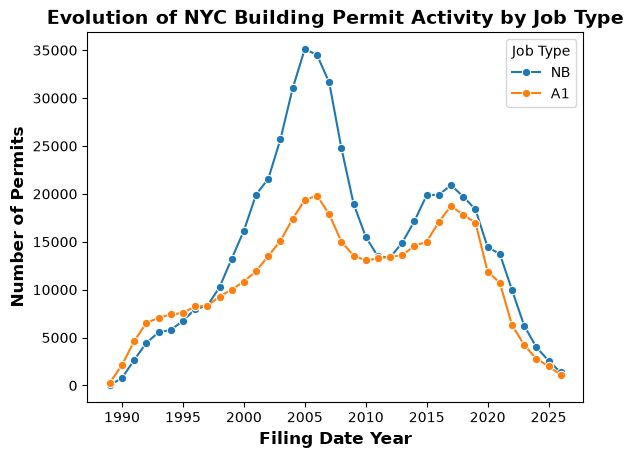

In [93]:

a = sns.lineplot(
    data=dataset_clean_groupby_month_year,
    x="Filing Date Year",
    y="size",
    hue="Job Type",
    marker="o",
    linewidth=1.5,
)

# Titles and labels
a.set_title(
    "Evolution of NYC Building Permit Activity by Job Type",
    fontsize=14,
    fontweight="bold",
)

a.set_xlabel("Filing Date Year", fontsize=12, fontweight="bold")
a.set_ylabel("Number of Permits", fontsize=12, fontweight="bold")





Now we look at the building permit count by Borough to understand which area has major activity.

In [94]:
dataset_total_permits_boroughs = dataset_clean_groupby_boroughs.groupby("BOROUGH", as_index=False).size().sort_values(by="size", ascending=False)

dataset_total_permits_boroughs

,BOROUGH,size
3,QUEENS,321069
1,BROOKLYN,311127
2,MANHATTAN,127675
4,STATEN ISLAND,126707
0,BRONX,104709


Text(0.5, 1, 'Total Number of Building Permits by Borough in New York City 1989-2026')

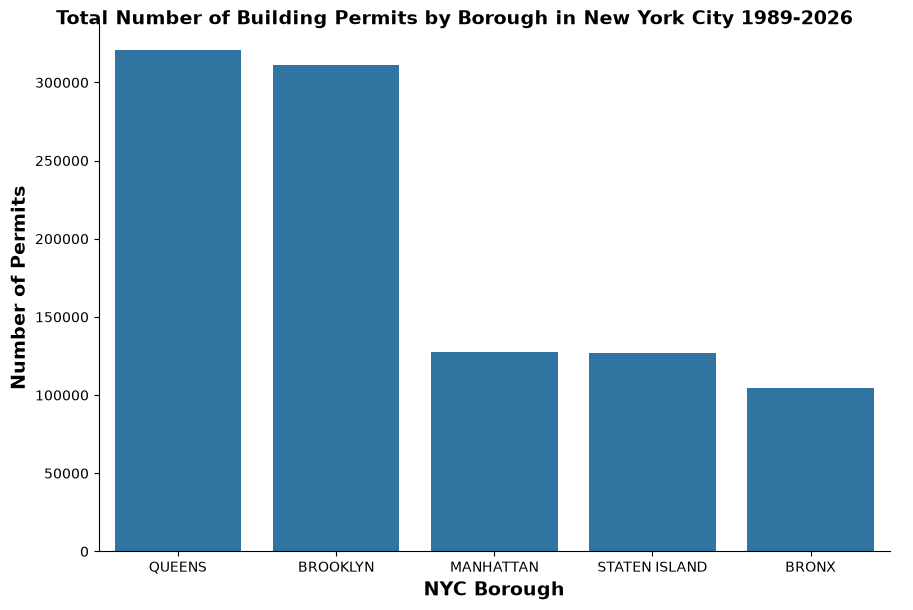

In [95]:
b = sns.catplot(
    data=dataset_total_permits_boroughs,
    x="BOROUGH",
    y="size",
    kind="bar",
    height=6,
    aspect=1.5
)

b.set_axis_labels("NYC Borough", "Number of Permits", fontsize=14,
    fontweight="bold")


b.figure.suptitle(
    "Total Number of Building Permits by Borough in New York City 1989-2026",
    fontsize=14,
    fontweight="bold",
    y=1
)


In [96]:
dataset_by_boroughs_permit_type =dataset_clean_groupby_boroughs.groupby(["BOROUGH", "Permit Type"],as_index=False).size().sort_values(by="size",ascending=False)

dataset_by_boroughs_permit_type["Permit Type Name"] = dataset_by_boroughs_permit_type["Permit Type"].map({"NB": "New Building", "AL": "Alteration", "PL" : "Plumbing", "SG" : "Sign"
, "FO": "Foundation", "DM": "Demolition", "EQ": "Construction Equipment", "EW": "Equipment Work"})

dataset_by_boroughs_permit_type

,BOROUGH,Permit Type,size,Permit Type Name
23,QUEENS,PL,84476,Plumbing
22,QUEENS,NB,77542,New Building
10,BROOKLYN,NB,74128,New Building
6,BROOKLYN,AL,73273,Alteration
11,BROOKLYN,PL,72796,Plumbing
18,QUEENS,AL,72514,Alteration
7,BROOKLYN,EQ,63580,Construction Equipment
19,QUEENS,EQ,60774,Construction Equipment
28,STATEN ISLAND,NB,58463,New Building
12,MANHATTAN,AL,57818,Alteration


Text(0.5, 1, 'Building Permits by Borough and Permit Type in New York City 1989-2026')

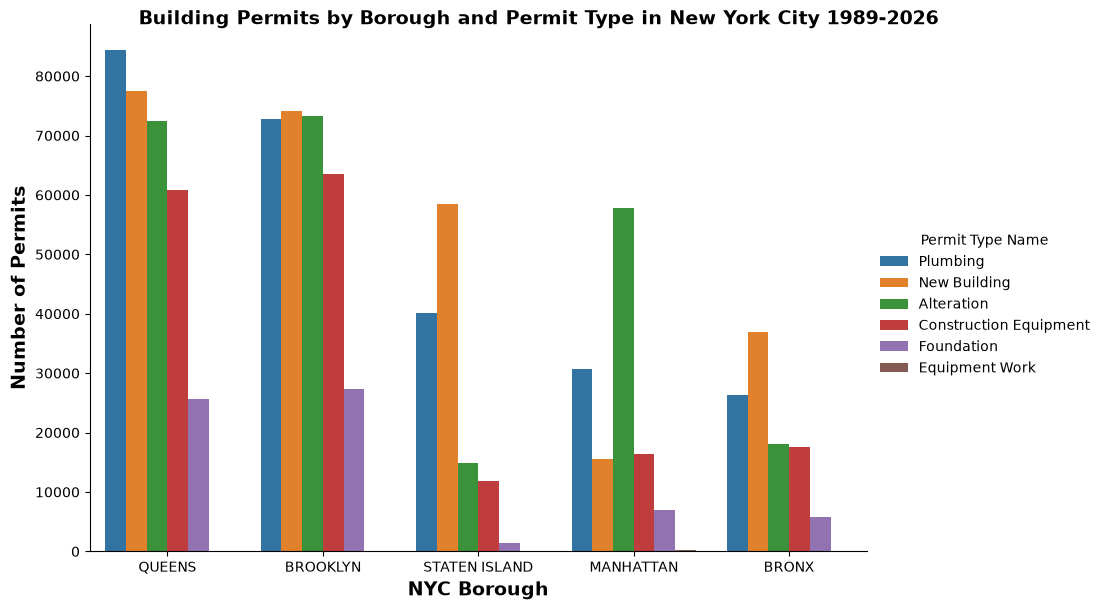

In [97]:
g = sns.catplot(
    data=dataset_by_boroughs_permit_type,
    x="BOROUGH",
    y="size",
    hue="Permit Type Name",
    kind="bar",
    height=6,
    aspect=1.5
)

g.set_axis_labels("NYC Borough", "Number of Permits", fontsize=14,
    fontweight="bold")


g.figure.suptitle(
    "Building Permits by Borough and Permit Type in New York City 1989-2026",
    fontsize=14,
    fontweight="bold",
    y=1
)


Now that we have a better idea of the Boroughs with more activity, we can also look at specific Building Permits. Each record represents  Each row/record in this dataset represents the life cycle of one permit for one work type. Meaning that each permit for a specific location (the building has a unique identifier in the `Bin #` column) might have other types associated. Since the `Work Type` column has been deleted because of missing values, I might only explore how many times each permit has been referenced in the dataset to find out the area where the one that had more requests is located. I can also look at the `Permit Type` to get a sense of the different types of permit that were issued.

In [103]:
dataset_repeated_permits = dataset_clean_groupby_boroughs.groupby(["BOROUGH", "Bin #"], as_index=False).size().sort_values(by="size", ascending=False)

dataset_repeated_permits.head(10)

,BOROUGH,Bin #,size
100395,QUEENS,4063940,111
87634,MANHATTAN,1081783,86
64789,BROOKLYN,3396741,86
90179,MANHATTAN,1090495,84
90150,MANHATTAN,1090459,84
53130,BROOKLYN,3329285,79
33123,BROOKLYN,3068099,78
36649,BROOKLYN,3094511,75
184340,STATEN ISLAND,5164632,71
67684,BROOKLYN,3418352,70


This table gives us important information. Now we know that our data, contains information of building permits for around 190,000 buildings in New York City. Not only that but we also now that the building with the most records in the database is located in Queens with 111 records in total.

So now, we could answer the question: ** What are the top 100 buildings with more requests in the database located in the city?**

In [ ]:
subset_dataset_top_100 = dataset_repeated_permits.head(100)

# To get the total number of buildings for each BOROUGH in the top 100 with more records in the database.
subset_dataset_top_100.groupby("BOROUGH", as_index=False).size().sort_values(by="size", ascending=False)




,BOROUGH,size
1,BROOKLYN,39
3,QUEENS,28
2,MANHATTAN,26
4,STATEN ISLAND,4
0,BRONX,3


In [105]:

# To get the total number of records for each BOROUGH in the top 100 records.
subset_dataset_top_100.groupby("BOROUGH", as_index=False)["size"].sum().sort_values(by="size", ascending=False)

,BOROUGH,size
1,BROOKLYN,2296
3,QUEENS,1576
2,MANHATTAN,1537
4,STATEN ISLAND,242
0,BRONX,166


To conclude this section, I will map the top 100 buildings with the highest number of records in the dataset across New York City. By visualizing their geographic distribution, we can identify potential spatial patterns, areas of concentration, and possible clusters of building permit activity. This will provide a foundation for further spatial analysis and help us understand whether these buildings are concentrated in specific neighborhoods or boroughs.

In [106]:
subset_dataset_top_100

,BOROUGH,Bin #,size
100395,QUEENS,4063940,111
87634,MANHATTAN,1081783,86
64789,BROOKLYN,3396741,86
90179,MANHATTAN,1090495,84
90150,MANHATTAN,1090459,84
...,...,...,...
68994,BROOKLYN,3425507,47
89604,MANHATTAN,1088827,47
147113,QUEENS,4539358,47
147221,QUEENS,4539510,47


In [172]:
building_identifier = subset_dataset_top_100["Bin #"].tolist() 

extract_lat_long_top_hundred = dataset_subset_clean_for_analysis[dataset_subset_clean_for_analysis["Bin #"].isin(building_identifier)]

only_top_100 = extract_lat_long_top_hundred.groupby("Bin #")[["LONGITUDE", "LATITUDE"]].first().reset_index()

only_top_100

,Bin #,LONGITUDE,LATITUDE
0,1012147,-74.006993,40.738149
1,1014081,-73.996969,40.743776
2,1028168,-73.979865,40.772885
3,1030994,-73.984517,40.781056
4,1031181,-73.970946,40.783101
...,...,...,...
95,4833509,-73.790341,40.722285
96,5154342,-74.188273,40.528065
97,5164632,-74.078337,40.646172
98,5164735,-74.074594,40.582243


In [149]:
#LOADING BOROUGHS SHAPEFILE
shapefile_path_BOROUGHS = "geographic_data/BOROUGHS/nybb.shp"
new_york_BOROUGHS = gpd.read_file(shapefile_path_BOROUGHS)

#LOADING NTA SHAPEFILES
shapefile_path_NTA = "geographic_data/NTA/nynta2020.shp"
new_york_NTA = gpd.read_file(shapefile_path_NTA)


In [164]:
#Exploring the data in the BOROUGH shapefile
# new_york_BOROUGHS.info() --> We will use the geometry column to plot the boroughs on a map and also the BoroName column to show the borough names on the popup.

# Exploring the data in the NTA shapefile
# new_york_NTA.info() --> We will use the geometry column to plot the neighborhoods on a map and also the NTAName column to show the neighborhood tabulation area names on the popup.

First, we need to make sure that the coordinates are using the correct CRS (latitudes and longitudes) so we can use folium to display the layers.

In [ ]:
boroughs = new_york_BOROUGHS.to_crs(epsg=4326)
nta = new_york_NTA.to_crs(epsg=4326)

In [175]:
m = folium.Map(
    location=[40.7128, -74.0060], # NYC AREA    
    tiles="OpenStreetMap",
    zoom_start=11,
    width="100%",
    height="100%"
)

# Add NYC borough boundaries

borough_group = folium.FeatureGroup(name="NYC Boroughs").add_to(m)

for _, r in boroughs.iterrows():
    sim_geo = gpd.GeoSeries([r["geometry"]]).simplify(tolerance=0.001)
    
    geo_j = folium.GeoJson(
        data=sim_geo.to_json(),
        style_function=lambda x: {
            "fillColor": "orange",
            "color": "black",
            "weight": 2,
            "fillOpacity": 0.25
        },
        tooltip=r["BoroName"]
    )
    geo_j.add_to(borough_group)

# Add NYC neighborhood boundaries (NTA)

nta_group = folium.FeatureGroup(name="NYC Neighborhoods", show=False).add_to(m)

for _, r in nta.iterrows():
    sim_geo = gpd.GeoSeries([r["geometry"]]).simplify(tolerance=0.001)

    geo_j = folium.GeoJson(
        data=sim_geo.to_json(),
        style_function=lambda x: {
            "fillColor": "blue",
            "color": "black",
            "weight": 1.5,
            "fillOpacity": 0.15
        },
        tooltip=r["NTAName"]
    )

    geo_j.add_to(nta_group)

buildings_group = folium.FeatureGroup(name="NYC Top 100 Buildings").add_to(m)

for _, r in only_top_100.iterrows():

    geo_j = folium.Marker(
        location=[r["LATITUDE"], r["LONGITUDE"]],
        popup= r["Bin #"]
    )
    geo_j.add_to(buildings_group)

# Add a layer toggle control
folium.LayerControl().add_to(m)

# Save the map
os.makedirs("map_result", exist_ok=True)
m.save("map_result/new_york_city_map.html")
